# Scraping de todos los equipos — corrida post-fecha (Primera Nacional)

Baja los partidos de **todos los equipos de Primera Nacional 2026** — Zona A (los 18 rivales
directos de Chaco) y Zona B (los otros 18 equipos de la misma categoría) — reutilizando
exactamente las mismas funciones del pre-partido: `scrape_rival_recent` y `scrape_rival_managers`.

Para Liga Profesional (otro torneo, otros equipos) usar el notebook gemelo:
`notebooks/liga_profesional/scraping_todos_los_equipos.ipynb`.

**Cuándo correrlo:** una vez terminada cada fecha. Como el scraper es incremental (los partidos que
ya están completos se saltean sin llamadas de red), cada corrida solo baja lo nuevo de la fecha.

**Para qué:** tener los datos de todos los equipos ya en disco, así el análisis pre-partido no tiene
que esperar el scraping del rival de turno y se pueden armar estadísticas comparativas de la liga
(Zona A y Zona B comparten el mismo `config.RIVALS`, así que salen con las mismas funciones).

**Qué baja de cada partido:** lo mismo que un partido de For Ever — los 9 endpoints crudos
(`event`, `statistics`, `lineups`, `incidents`, `shotmap`, `average_positions`, `graph`,
`best_players`, `heatmaps`) más el DT (`managers`), y los 9 CSV limpios, con el lineups ya
enriquecido con cambios y tarjetas.

Las pausas entre requests son las de siempre: `config.MIN_DELAY`–`config.MAX_DELAY` segundos.

> **Ojo con la primera corrida.** Los equipos que están en cero arrancan de ~19 partidos cada uno,
> y cada partido son 8 requests + ~22 de heatmaps. Son varias horas — con las dos zonas (36
> equipos) es una corrida grande, pensada para dejar en background (ver `scripts/scrape_overnight.py`).
> De ahí en adelante, cada corrida post-fecha es solo un partido nuevo por equipo.


In [ ]:
import os, sys, time, random

%load_ext autoreload
%autoreload 2

if os.path.basename(os.getcwd()) in ('primera_nacional', 'liga_profesional'):
    os.chdir('..')
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
PROJECT_ROOT = os.getcwd()
sys.path.insert(0, PROJECT_ROOT)

import config
from src.scraping.rivals_scraper import (
    scrape_rival_recent, scrape_rival_managers, rival_already_scraped,
)

# ============================================================
# CONFIGURAR ACÁ
SEASON = '2026'
# Zona A (18 rivales directos de Chaco) + Zona B (18 equipos de la misma
# categoría). Algunos slugs de Zona B reusan la clave de Zona A/2025 cuando es
# el mismo equipo de SofaScore (ver comentario en config.RIVALS_ZONA_B_2026),
# así que dict.fromkeys() deduplica sin perder el orden ni pisar nombres.
EQUIPOS  = list(dict.fromkeys(list(config.RIVALS_2026) + list(config.RIVALS_ZONA_B_2026)))
CON_DT   = True                       # bajar tambien el DT de cada partido (/managers)
HEATMAPS = True                       # mapas de calor por jugador (~22 requests extra por partido)
HEADLESS = False                      # False = con ventana, igual que el pre-partido
QUICK    = True                       # corrida post-fecha: solo mira las últimas 2 páginas del
                                      # feed de cada equipo (el partido nuevo siempre está ahí).
                                      # Poné False para la PRIMERA corrida / un backfill completo.
RETRY_EMPTY = False                   # True para reintentar endpoints que SofaScore no había
                                      # publicado (ej. shotmaps de la última fecha que cargan tarde)
# ============================================================

print(f'Temporada {SEASON} · {len(EQUIPOS)} equipos (Zona A + Zona B)')
print(f'Modo: {"QUICK (post-fecha)" if QUICK else "COMPLETO (backfill)"}')
print(f'Pausa entre endpoints: {config.MIN_DELAY_EP}-{config.MAX_DELAY_EP} s · entre partidos: {config.MIN_DELAY}-{config.MAX_DELAY} s')
for s in EQUIPOS:
    zona = 'A' if s in config.RIVALS_2026 else 'B'
    print(f'  · [{zona}] {s:26s} {config.RIVALS[s]["name"]}')


Temporada 2026 · 35 equipos (Zona A + Zona B)
Modo: QUICK (post-fecha)
Pausa entre endpoints: 1.5-3.0 s · entre partidos: 4-8 s
  · [A] acassuso                   Acassuso
  · [A] all_boys                   All Boys
  · [A] almirante_brown            Almirante Brown
  · [A] central_norte              Central Norte de Salta
  · [A] ciudad_de_bolivar          Ciudad de Bolívar
  · [A] colon                      Club Atlético Colón
  · [A] defensores_de_belgrano     Defensores de Belgrano
  · [A] deportivo_madryn           Deportivo Madryn
  · [A] deportivo_moron            Deportivo Morón
  · [A] estudiantes_caseros        Estudiantes de Buenos Aires
  · [A] ferro_carril_oeste         Club Ferro Carril Oeste
  · [A] gimnasia_de_jujuy          Gimnasia Jujuy
  · [A] godoy_cruz                 Godoy Cruz
  · [A] los_andes                  Los Andes
  · [A] mitre                      CA Mitre
  · [A] racing_de_cordoba          Racing de Córdoba
  · [A] san_miguel                 San Miguel


## 1. Qué falta bajar

Antes de disparar nada, mirá cuántos partidos hay ya en disco por equipo.


In [2]:
from src.scraping.chaco_scraper import _match_done

def partidos_en_disco(slug, season=SEASON):
    """(completos, incompletos). Completo = mismo criterio que el scraper de Chaco.
    Los partidos bajados con la version vieja del scraper cuentan como incompletos:
    les faltan event/average_positions/momentum/best_players/heatmaps y se vuelven
    a bajar enteros en la proxima corrida."""
    d = os.path.join(config.rivals_dir(season), slug)
    if not os.path.isdir(d):
        return 0, 0
    dirs = [os.path.join(d, m) for m in os.listdir(d) if os.path.isdir(os.path.join(d, m))]
    ok = sum(1 for m in dirs if _match_done(m))
    return ok, len(dirs) - ok

print(f'{"EQUIPO":28s} {"COMPLETOS":>9s} {"A REBAJAR":>9s}')
for slug in EQUIPOS:
    ok, falta = partidos_en_disco(slug)
    print(f'{config.RIVALS[slug]["name"]:28s} {ok:>9d} {falta:>9d}')


EQUIPO                       COMPLETOS A REBAJAR
Acassuso                            34         0
All Boys                            34         0
Almirante Brown                     34         0
Central Norte de Salta              34         0
Ciudad de Bolívar                   34         0
Club Atlético Colón                 34         0
Defensores de Belgrano              34         0
Deportivo Madryn                    34         0
Deportivo Morón                     34         0
Estudiantes de Buenos Aires         34         0
Club Ferro Carril Oeste             34         0
Gimnasia Jujuy                      34         0
Godoy Cruz                          34         0
Los Andes                           34         0
CA Mitre                            33         1
Racing de Córdoba                   34         0
San Miguel                          34         0
San Telmo                           34         0
Tristán Suárez                      34         0
Temperley           

## 2. Scraping de todos los equipos

Loop sobre los equipos llamando a las mismas funciones del pre-partido. `n_matches=None` baja
**todos** los partidos jugados de la temporada, que es lo que el pre-partido necesita para que
formaciones, mejor once y disciplina salgan sobre la muestra completa.

Es reanudable: si se corta a mitad, volvés a correr la celda y sigue donde estaba.


In [3]:
resumen = {}
fallidos = {}
sep = '=' * 70

for i, slug in enumerate(EQUIPOS, 1):
    nombre = config.RIVALS[slug]['name']
    print(f'\n{sep}\n[{i}/{len(EQUIPOS)}] {nombre}  ({slug})\n{sep}')
    try:
        mks = scrape_rival_recent(slug, n_matches=None, season=SEASON,
                                  headless=HEADLESS, include_heatmaps=HEATMAPS,
                                  quick=QUICK, retry_empty=RETRY_EMPTY)
        if CON_DT:
            scrape_rival_managers(slug, season=SEASON, headless=HEADLESS)
        resumen[slug] = len(mks)
    except Exception as e:
        fallidos[slug] = repr(e)
        print(f'  ERROR en {nombre}: {e}')

    # Misma pausa que el scraper usa entre partidos, ahora entre equipos.
    if i < len(EQUIPOS):
        time.sleep(random.uniform(config.MIN_DELAY, config.MAX_DELAY))

print(f'\n\nListo. {len(resumen)}/{len(EQUIPOS)} equipos ok.')
if fallidos:
    print('Fallidos (volvé a correr la celda: arranca donde quedó):')
    for slug, err in fallidos.items():
        print(f'  · {slug}: {err}')



[1/35] Acassuso  (acassuso)
Scrapeando TODOS los partidos de Acassuso en la temporada 2026 (id=112491)...
  ERROR en Acassuso: HTTPConnectionPool(host='localhost', port=59937): Max retries exceeded with url: /session/bc72449a8bafb93202a3228e2b2071f5/source (Caused by NewConnectionError('<urllib3.connection.HTTPConnection object at 0x00000140E065ABE0>: Failed to establish a new connection: [WinError 10061] No se puede establecer una conexión ya que el equipo de destino denegó expresamente dicha conexión'))

[2/35] All Boys  (all_boys)
Scrapeando TODOS los partidos de All Boys en la temporada 2026 (id=36834)...
  35 partidos en el feed.

  [1/35] ya está: 2026-02-14_vs_ca_mitre_h
  [2/35] ya está: 2026-02-22_vs_almirante_brown_a
  [3/35] ya está: 2026-03-01_vs_ciudad_de_bolivar_h
  [4/35] ya está: 2026-03-14_vs_deportivo_madryn_h
  [5/35] ya está: 2026-03-22_vs_central_norte_de_salta_a
  [6/35] ya está: 2026-03-29_vs_nueva_chicago_a
  [7/35] ya está: 2026-04-04_vs_club_ferro_carril_oest

## 3. Control final

Cuántos partidos quedó con cada equipo. Corriendo esto después de cada fecha, el número debería
subir de a uno por equipo.


In [4]:
ARCHIVOS = ['event_clean.csv', 'statistics_clean.csv', 'lineups_clean.csv',
            'incidents_clean.csv', 'shotmap_clean.csv', 'average_positions_clean.csv',
            'momentum_clean.csv', 'best_players_clean.csv', 'player_heatmaps_clean.csv']

print(f'{"EQUIPO":28s} {"COMPLETOS":>9s} {"HEATMAP":>7s} {"DT":>4s}')
total = 0
for slug in EQUIPOS:
    d = os.path.join(config.rivals_dir(SEASON), slug)
    ok, _ = partidos_en_disco(slug)
    hm = dt = 0
    if os.path.isdir(d):
        for m in os.listdir(d):
            mp = os.path.join(d, m)
            hm += os.path.exists(os.path.join(mp, 'player_heatmaps_clean.csv'))
            dt += os.path.exists(os.path.join(mp, 'raw', 'managers.json'))
    total += ok
    print(f'{config.RIVALS[slug]["name"]:28s} {ok:>9d} {hm:>7d} {dt:>4d}')
print(f'\nTotal de partidos de rivales completos: {total}')

# Chequeo fino: que ningun partido completo se haya quedado sin alguno de los 9 CSV.
faltantes = []
for slug in EQUIPOS:
    d = os.path.join(config.rivals_dir(SEASON), slug)
    if not os.path.isdir(d):
        continue
    for m in sorted(os.listdir(d)):
        mp = os.path.join(d, m)
        falta = [f for f in ARCHIVOS if not os.path.exists(os.path.join(mp, f))]
        if falta:
            faltantes.append((slug, m, falta))
if faltantes:
    print(f'\n{len(faltantes)} partidos con archivos faltantes:')
    for slug, m, falta in faltantes[:20]:
        print(f'  · {slug}/{m}: {", ".join(falta)}')
else:
    print('Todos los partidos tienen los 9 CSV.')


EQUIPO                       COMPLETOS HEATMAP   DT
Acassuso                            34      34   34
All Boys                            34      34   34
Almirante Brown                     34      34   34
Central Norte de Salta              34      34   34
Ciudad de Bolívar                   34      34   34
Club Atlético Colón                 34      34   34
Defensores de Belgrano              34      33   33
Deportivo Madryn                    34      32   34
Deportivo Morón                     34      33   34
Estudiantes de Buenos Aires         34      33   34
Club Ferro Carril Oeste             34      34   34
Gimnasia Jujuy                      34      32   34
Godoy Cruz                          34      33   34
Los Andes                           34      34   34
CA Mitre                            33      32   34
Racing de Córdoba                   34      33   34
San Miguel                          34      34   34
San Telmo                           34      33   34
Tristán Suár

## 3b. Auditoría de partidos incompletos

Lista lo que no se pudo bajar bien: *data base rota* (revisar el link), *pendiente de reintento* y *sin análisis en SofaScore* (no va a tener shotmap). Si aparece algo en las dos primeras, volvé a correr la celda 2 (con `RETRY_EMPTY = True` si hace falta).


In [5]:
from src.scraping.audit import print_audit
_ = print_audit(SEASON)



=== PENDIENTE DE REINTENTO — partido de los últimos 7 días ===
   (SofaScore suele cargar el shotmap/posiciones un par de días después;
    reintentar con retry_empty=True más adelante)
  · [rival] all_boys/2026-10-25_vs_racing_de_cordoba_a   (0d)   sin: shotmap,average_positions,graph,best_players

=== SIN ANÁLISIS EN SOFASCORE — no van a tener shotmap ===
   (partidos de menor cobertura; revisá el link solo si te interesa ese partido)
  · [chaco] Chaco For Ever/2026-08-16_vs_gimnasia_de_jujuy_a   no publicado: shotmap,average_positions,graph,best_players
  · [rival] almagro/2026-02-21_vs_san_martin_de_tucuman_h   no publicado: shotmap,average_positions,graph,best_players
  · [rival] defensores_de_belgrano/2026-10-19_vs_san_telmo_a   no publicado: shotmap,average_positions,graph,best_players
  · [rival] deportivo_madryn/2026-02-21_vs_deportivo_moron_h   no publicado: shotmap,average_positions,graph,best_players
  · [rival] deportivo_madryn/2026-08-16_vs_san_martin_de_tucuman_a   no p

## 3c. Refrescar tabla y fixture

El scraping de partidos **no** actualiza `standings.csv` ni `fixture.csv`. Sin esto, el post-partido y la proyección salen con la tabla de la fecha anterior.


In [6]:
import io, contextlib
from src.scraping.standings_scraper import fetch_standings
from src.scraping.fixture_scraper import fetch_fixture

# Los print con emoji revientan en cp1252 DESPUES de escribir el CSV; se silencian.
try:
    with contextlib.redirect_stdout(io.StringIO()):
        fetch_standings(season=SEASON, headless=False)
        fetch_fixture(season=SEASON, headless=False, verbose=False)
except Exception as e:
    print('Aviso al refrescar:', repr(e))

import pandas as pd
st = pd.read_csv(os.path.join('data', 'temporadas', SEASON, 'standings.csv'))
fx = pd.read_csv(os.path.join('data', 'temporadas', SEASON, 'fixture.csv'))
print('PJ maximo en la tabla:', st['matches_played'].max())
print(fx[fx['status_type'] != 'finished'].groupby('round').size().head(3).to_string())


PJ maximo en la tabla: 35
round
1    14
2    15
3    16


## 4. Análisis de temporada de cada rival

Las funciones de `analisis_temporada.ipynb` son genéricas: toman `match_keys` + `base_dir` y sacan la
perspectiva del equipo del sufijo `_h`/`_a` del match_key. Como los match_keys del rival están armados
desde SU óptica, corriendo lo mismo apuntando a `data/temporadas/{season}/rivals/{slug}/` sale el
análisis de temporada del rival, tal cual el nuestro (las columnas `chaco_*` de las tablas se leen
como "el equipo analizado").

Los gráficos van a `outputs/temporadas/{season}/rivals/{slug}/graficos/`.


In [7]:
import matplotlib
matplotlib.use('Agg')
import pandas as pd
from IPython.display import Image, display

from src.analysis.season import (
    build_season_table, season_stats, season_player_stats,
    top_scorers, most_used_players,
    threat_by_situation, markov_game_state, goals_by_time_window,
    is_home_match,
)
from src.visualization.season import (
    save_fig, plot_season_points, plot_xg_season, plot_top_players,
    plot_shotmap_4grid, plot_recent_form, plot_home_away_panel,
    plot_discipline, plot_threat_by_situation, plot_markov_transitions,
    plot_goals_by_time_window,
)

RATING_MIN_MIN = 450   # minutos minimos para el top de rating

def show(path):
    if path and os.path.exists(path):
        display(Image(filename=path))

def match_keys_rival(slug, season=SEASON):
    """Partidos completos del rival, en orden cronologico."""
    d = config.rival_data_dir(slug, season)
    if not os.path.isdir(d):
        return []
    return sorted(m for m in os.listdir(d) if _match_done(os.path.join(d, m)))

def analisis_temporada_equipo(slug, season=SEASON, graficos=True):
    """Analisis de temporada del rival, con las MISMAS funciones que el de For Ever.

    Devuelve (stats, season_df, player_df). Ojo: las columnas 'chaco_goals' /
    'chaco_xg' de las tablas se leen como "el equipo analizado" — el match_key del
    rival esta armado desde su optica, asi que is_home_match() resuelve bien de que
    lado mirar cada partido.

    Graficos -> outputs/temporadas/{season}/rivals/{slug}/graficos/
    """
    nombre   = config.RIVALS[slug]['name']
    base_dir = config.rival_data_dir(slug, season)
    mks      = match_keys_rival(slug, season)
    if not mks:
        print(f'{nombre}: sin partidos completos, se saltea.')
        return None, None, None

    season_df = build_season_table(mks, base_dir)
    stats     = season_stats(season_df)
    player_df = season_player_stats(mks, base_dir)

    if not graficos:
        return stats, season_df, player_df

    plots_dir = config.rival_plots_dir(slug, season)
    os.makedirs(plots_dir, exist_ok=True)
    p = lambda f: os.path.join(plots_dir, f)

    save_fig(plot_season_points(season_df), p('puntos_acumulados.png'))

    fig = plot_xg_season(season_df)
    if fig:
        save_fig(fig, p('xg_temporada.png'))

    plot_recent_form(season_df, window=5, season=season, save_path=p('forma_reciente.png'))
    plot_home_away_panel(season_df, season=season, save_path=p('local_visitante.png'))

    if not player_df.empty:
        save_fig(plot_top_players(player_df, metric='minutos', top_n=15), p('top_minutos.png'))

        rating_df = player_df[player_df['minutos'] >= RATING_MIN_MIN].dropna(subset=['rating_promedio'])
        if not rating_df.empty:
            xmin = max(4.0, float(rating_df['rating_promedio'].min()) - 0.3)
            save_fig(plot_top_players(rating_df, metric='rating_promedio', top_n=15, xmin=xmin),
                     p('top_rating.png'))

        plot_discipline(player_df, season=season, save_path=p('disciplina.png'))

    # Shotmap acumulado: solo los remates del equipo analizado
    shots = []
    for mk in mks:
        sp = os.path.join(base_dir, mk, 'shotmap_clean.csv')
        if os.path.exists(sp):
            df_s = pd.read_csv(sp)
            shots.append(df_s[df_s['isHome'] == is_home_match(mk)])
    if shots:
        df_shots = pd.concat(shots, ignore_index=True)
        save_fig(plot_shotmap_4grid(df_shots, team_label=nombre,
                                    title=f'Distribucion de Tiros - {nombre} {season}'),
                 p('shotmap_temporada.png'))

    # Los mismos analisis finos que le corremos al Negro
    thr = threat_by_situation(mks, base_dir)
    if thr is not None and not thr.empty:
        plot_threat_by_situation(thr, season=season, save_path=p('amenaza_por_situacion.png'))

    matrix_df, transitions_df = markov_game_state(mks, base_dir)
    if matrix_df is not None and not matrix_df.empty:
        plot_markov_transitions(matrix_df, transitions_df, season=season,
                                save_path=p('markov_estado_marcador.png'))

    win_df = goals_by_time_window(mks, base_dir)
    if win_df is not None and not win_df.empty:
        plot_goals_by_time_window(win_df, season=season, save_path=p('goles_por_ventana.png'))

    return stats, season_df, player_df

print('analisis_temporada_equipo() listo.')


analisis_temporada_equipo() listo.


In [8]:
# Corre el analisis de temporada de los equipos y arma la tabla comparativa de
# la liga, UNA POR ZONA (Zona A y Zona B no se cruzan entre si, asi que no
# tiene sentido ordenarlas juntas por puntos). Es solo lectura de disco +
# graficos: no toca la red, se puede repetir cuantas veces quieras.
temporadas = {}
filas_por_zona = {'A': [], 'B': []}

for slug in EQUIPOS:
    zona = 'A' if slug in config.RIVALS_2026 else 'B'
    nombre = config.RIVALS[slug]['name']
    stats, season_df, player_df = analisis_temporada_equipo(slug, SEASON)
    if not stats:
        continue
    temporadas[slug] = {'stats': stats, 'season_df': season_df, 'player_df': player_df}
    filas_por_zona[zona].append({
        'equipo': nombre,
        'PJ':  stats['partidos'],
        'V':   stats['victorias'],
        'E':   stats['empates'],
        'D':   stats['derrotas'],
        'Pts': stats['puntos'],
        'GF':  stats['goles_favor'],
        'GC':  stats['goles_contra'],
        'DG':  stats['diferencia_goles'],
        'xGF': stats['xg_favor'],
        'xGC': stats['xg_contra'],
        'local':      stats['rendimiento_local'],
        'visitante':  stats['rendimiento_visitante'],
    })
    print(f"OK [{zona}] {nombre:28s} {stats['partidos']:>2d} PJ | {stats['puntos']:>2d} pts | "
          f"{stats['goles_favor']}-{stats['goles_contra']}")

ligas = {}
for zona, filas in filas_por_zona.items():
    if not filas:
        continue
    liga = pd.DataFrame(filas).sort_values(['Pts', 'DG', 'GF'], ascending=False).reset_index(drop=True)
    liga.index += 1
    ligas[zona] = liga
    print(f'\n=== Zona {zona} segun nuestros propios datos ===')
    print(liga.to_string())

    liga_csv = os.path.join(config.OUTPUTS_DIR, 'temporadas', SEASON, 'rivals',
                            f'liga_resumen_zona_{zona.lower()}.csv')
    os.makedirs(os.path.dirname(liga_csv), exist_ok=True)
    liga.to_csv(liga_csv, index=False, encoding='utf-8')
    print(f'Guardado: {liga_csv}')


OK [A] Acassuso                     34 PJ | 33 pts | 24-35
OK [A] All Boys                     34 PJ | 35 pts | 19-29
OK [A] Almirante Brown              34 PJ | 48 pts | 28-24
OK [A] Central Norte de Salta       34 PJ | 37 pts | 23-31
OK [A] Ciudad de Bolívar            34 PJ | 51 pts | 30-29
OK [A] Club Atlético Colón          34 PJ | 54 pts | 41-27
OK [A] Defensores de Belgrano       34 PJ | 38 pts | 25-32
OK [A] Deportivo Madryn             34 PJ | 54 pts | 47-30
OK [A] Deportivo Morón              34 PJ | 58 pts | 51-36
OK [A] Estudiantes de Buenos Aires  34 PJ | 48 pts | 34-33
OK [A] Club Ferro Carril Oeste      34 PJ | 65 pts | 38-28
OK [A] Gimnasia Jujuy               34 PJ | 55 pts | 50-43
OK [A] Godoy Cruz                   34 PJ | 60 pts | 48-32
OK [A] Los Andes                    34 PJ | 41 pts | 26-25
OK [A] CA Mitre                     33 PJ | 36 pts | 29-39
OK [A] Racing de Córdoba            34 PJ | 40 pts | 30-39
OK [A] San Miguel                   34 PJ | 32 pts | 27-

## 5. Un equipo en detalle

Poné el slug del próximo rival y mirá su temporada acá mismo: tabla, goleadores, más utilizados y los
gráficos que se acaban de generar. Con esto el pre-partido arranca con la mitad del trabajo hecho.


=== San Miguel · Temporada 2026 ===
34 PJ | 6V-14E-14D | 32 pts
Goles: 27 a favor / 41 en contra
xG: 37.11 favor / 38.14 contra
Local: 5V-5E-7D  |  Visitante: 1V-9E-7D

      date                  opponent     venue result  goles  goles_rival
2026-02-13    Central Norte De Salta     Local      W      1            0
2026-02-21   Club Ferro Carril Oeste Visitante      D      1            1
2026-02-28            Chaco For Ever     Local      W      2            0
2026-03-14                 San Telmo     Local      D      1            1
2026-03-21         Racing De Cordoba     Local      L      1            2
2026-03-28                Colegiales Visitante      D      0            0
2026-04-04       Club Atletico Colon Visitante      L      0            3
2026-04-11           Deportivo Moron     Local      W      2            1
2026-04-18                Godoy Cruz Visitante      D      0            0
2026-04-25                 Los Andes     Local      L      0            2
2026-04-30       

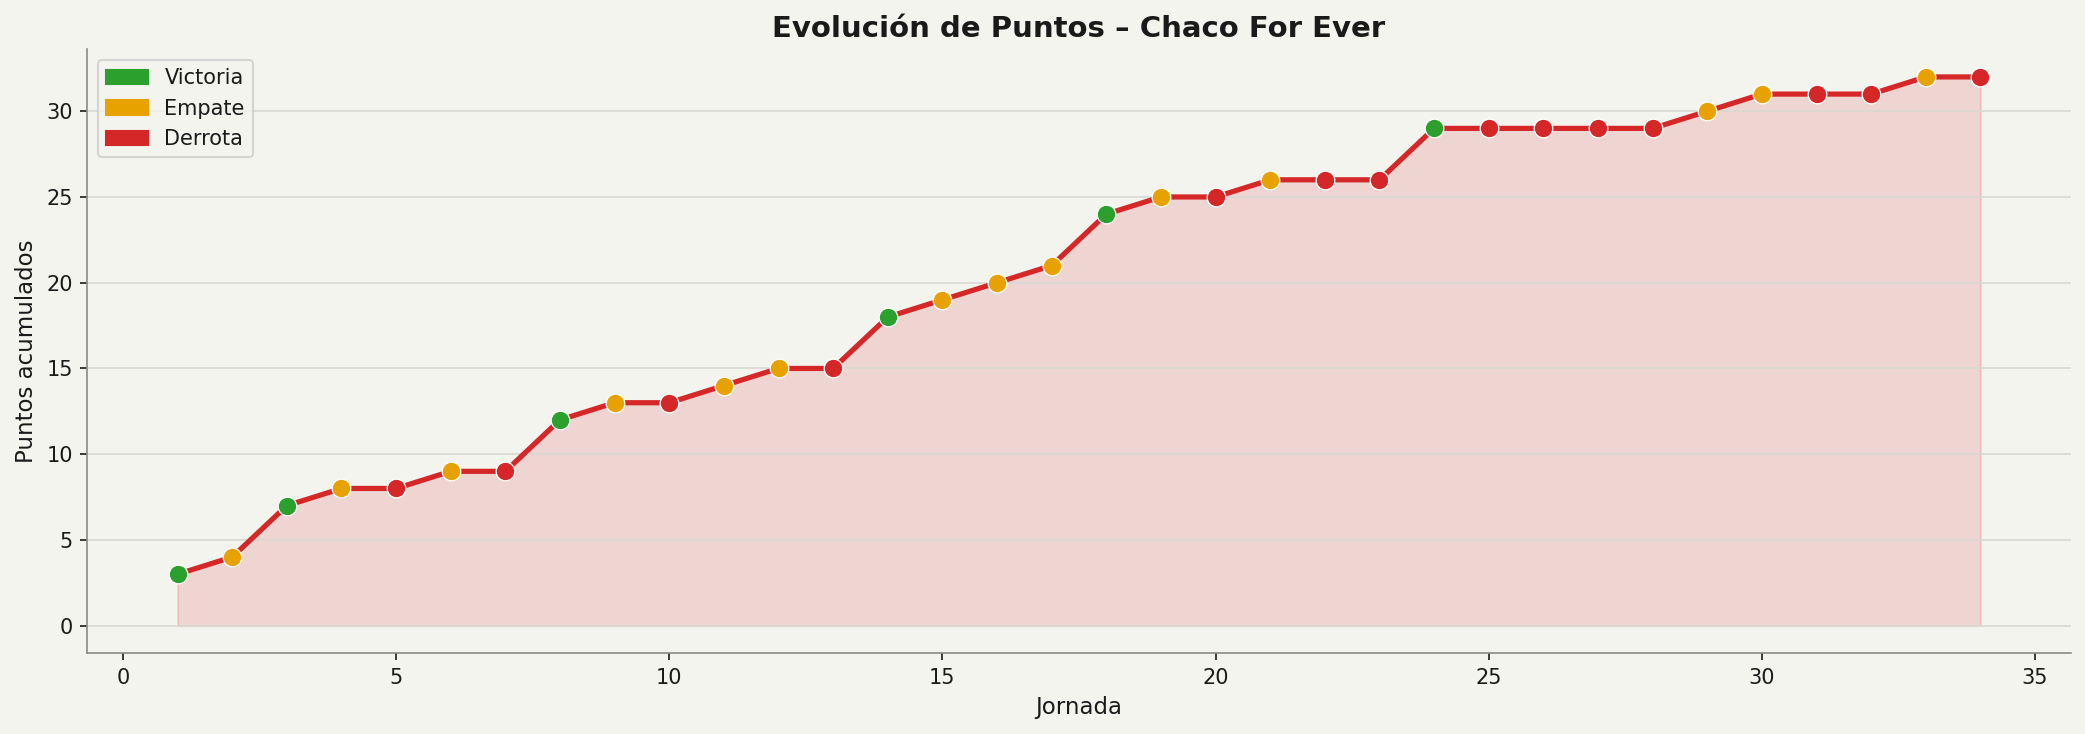

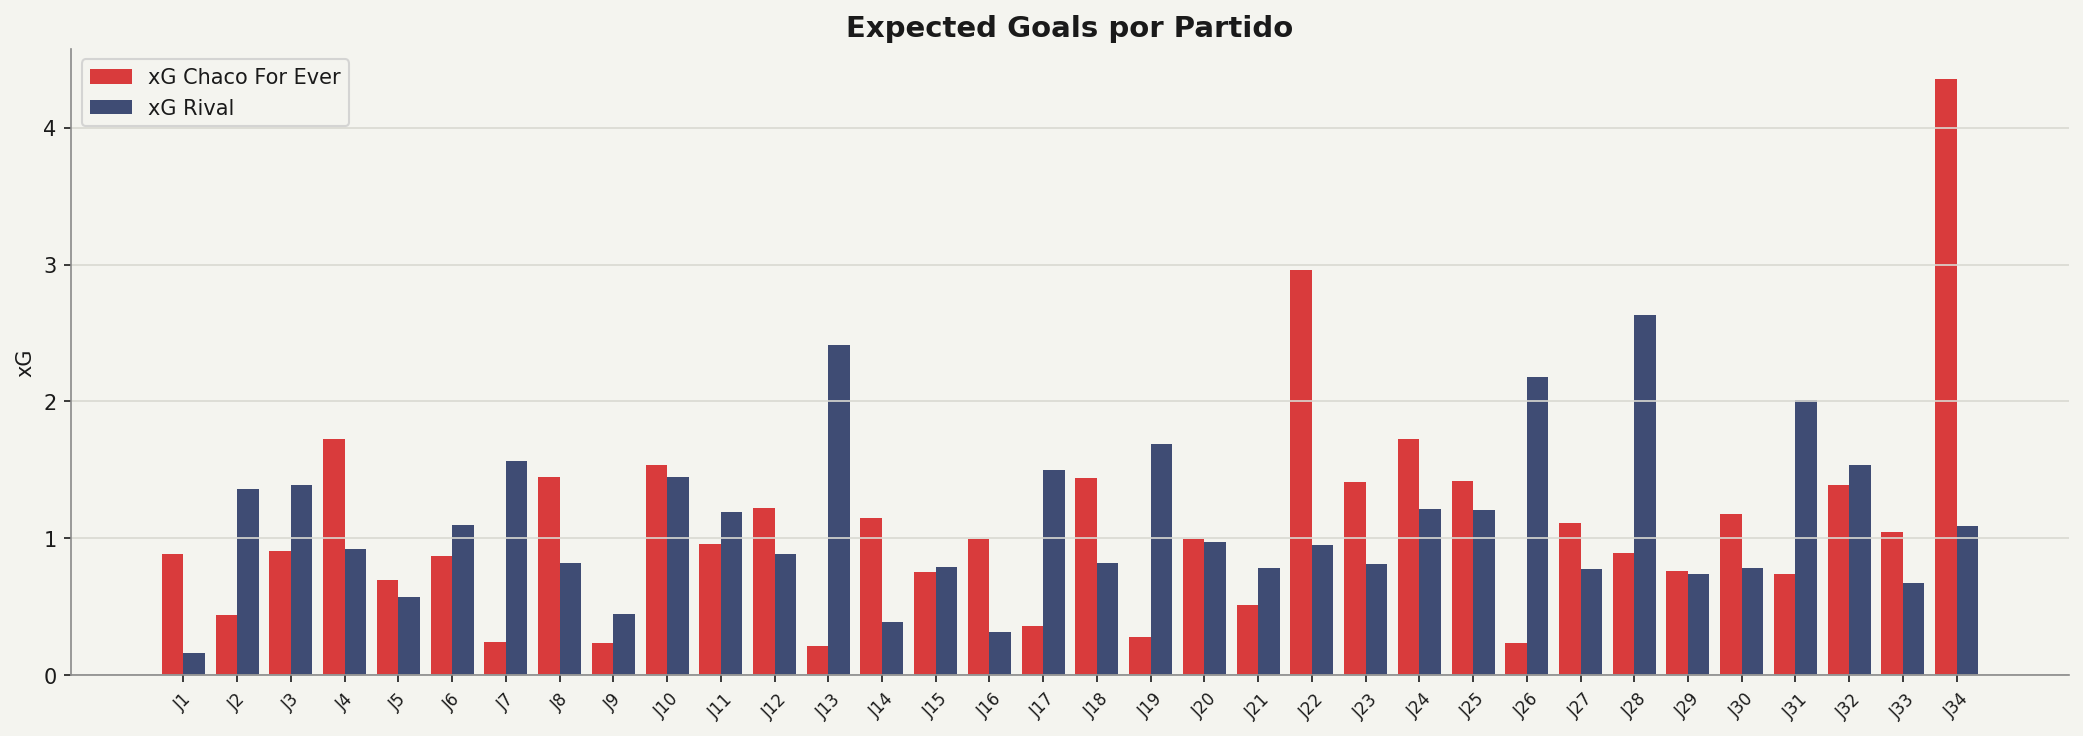

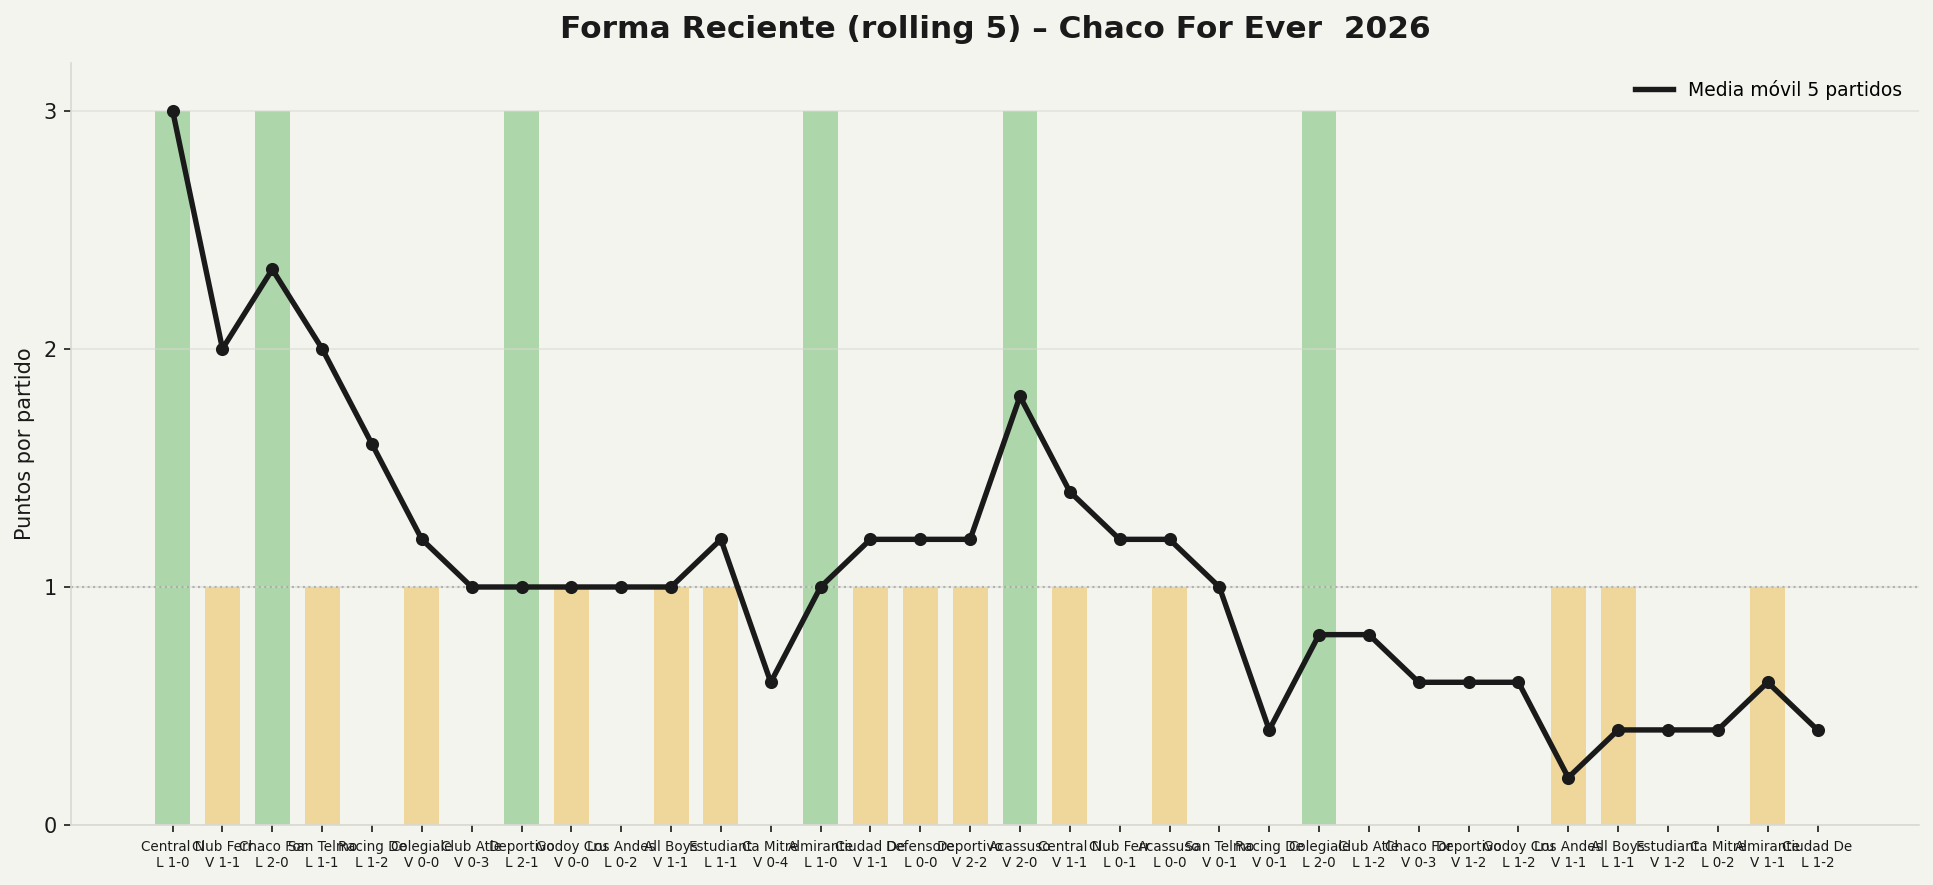

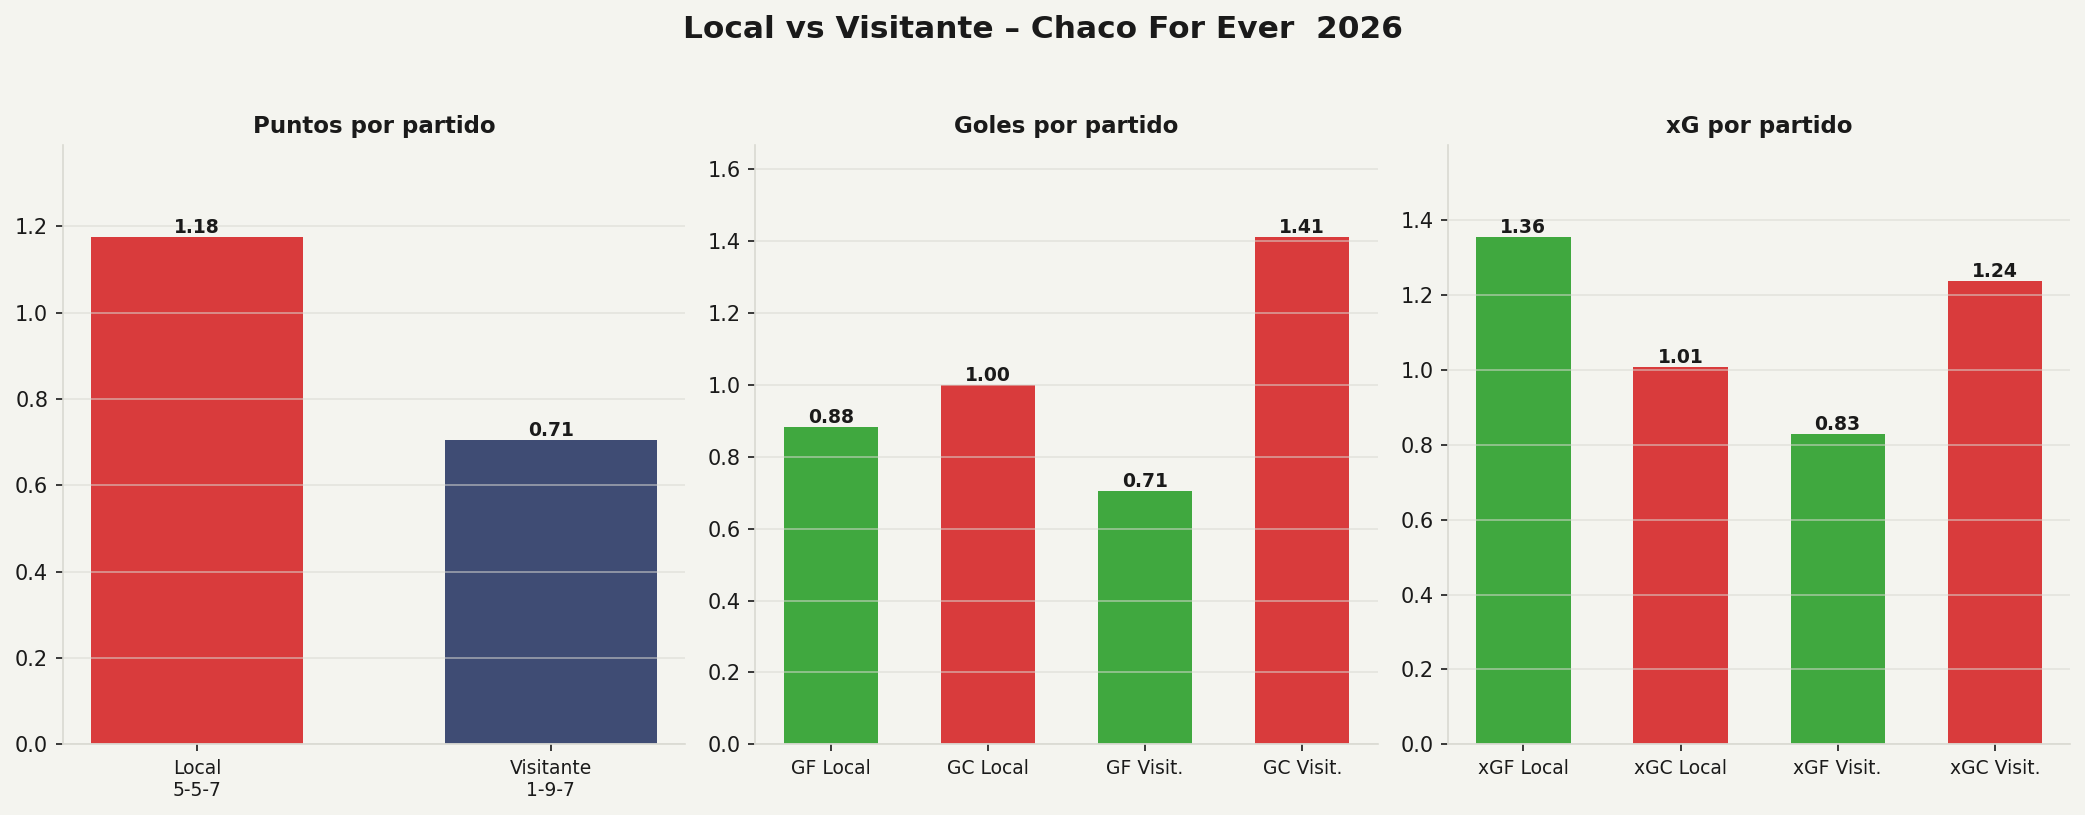

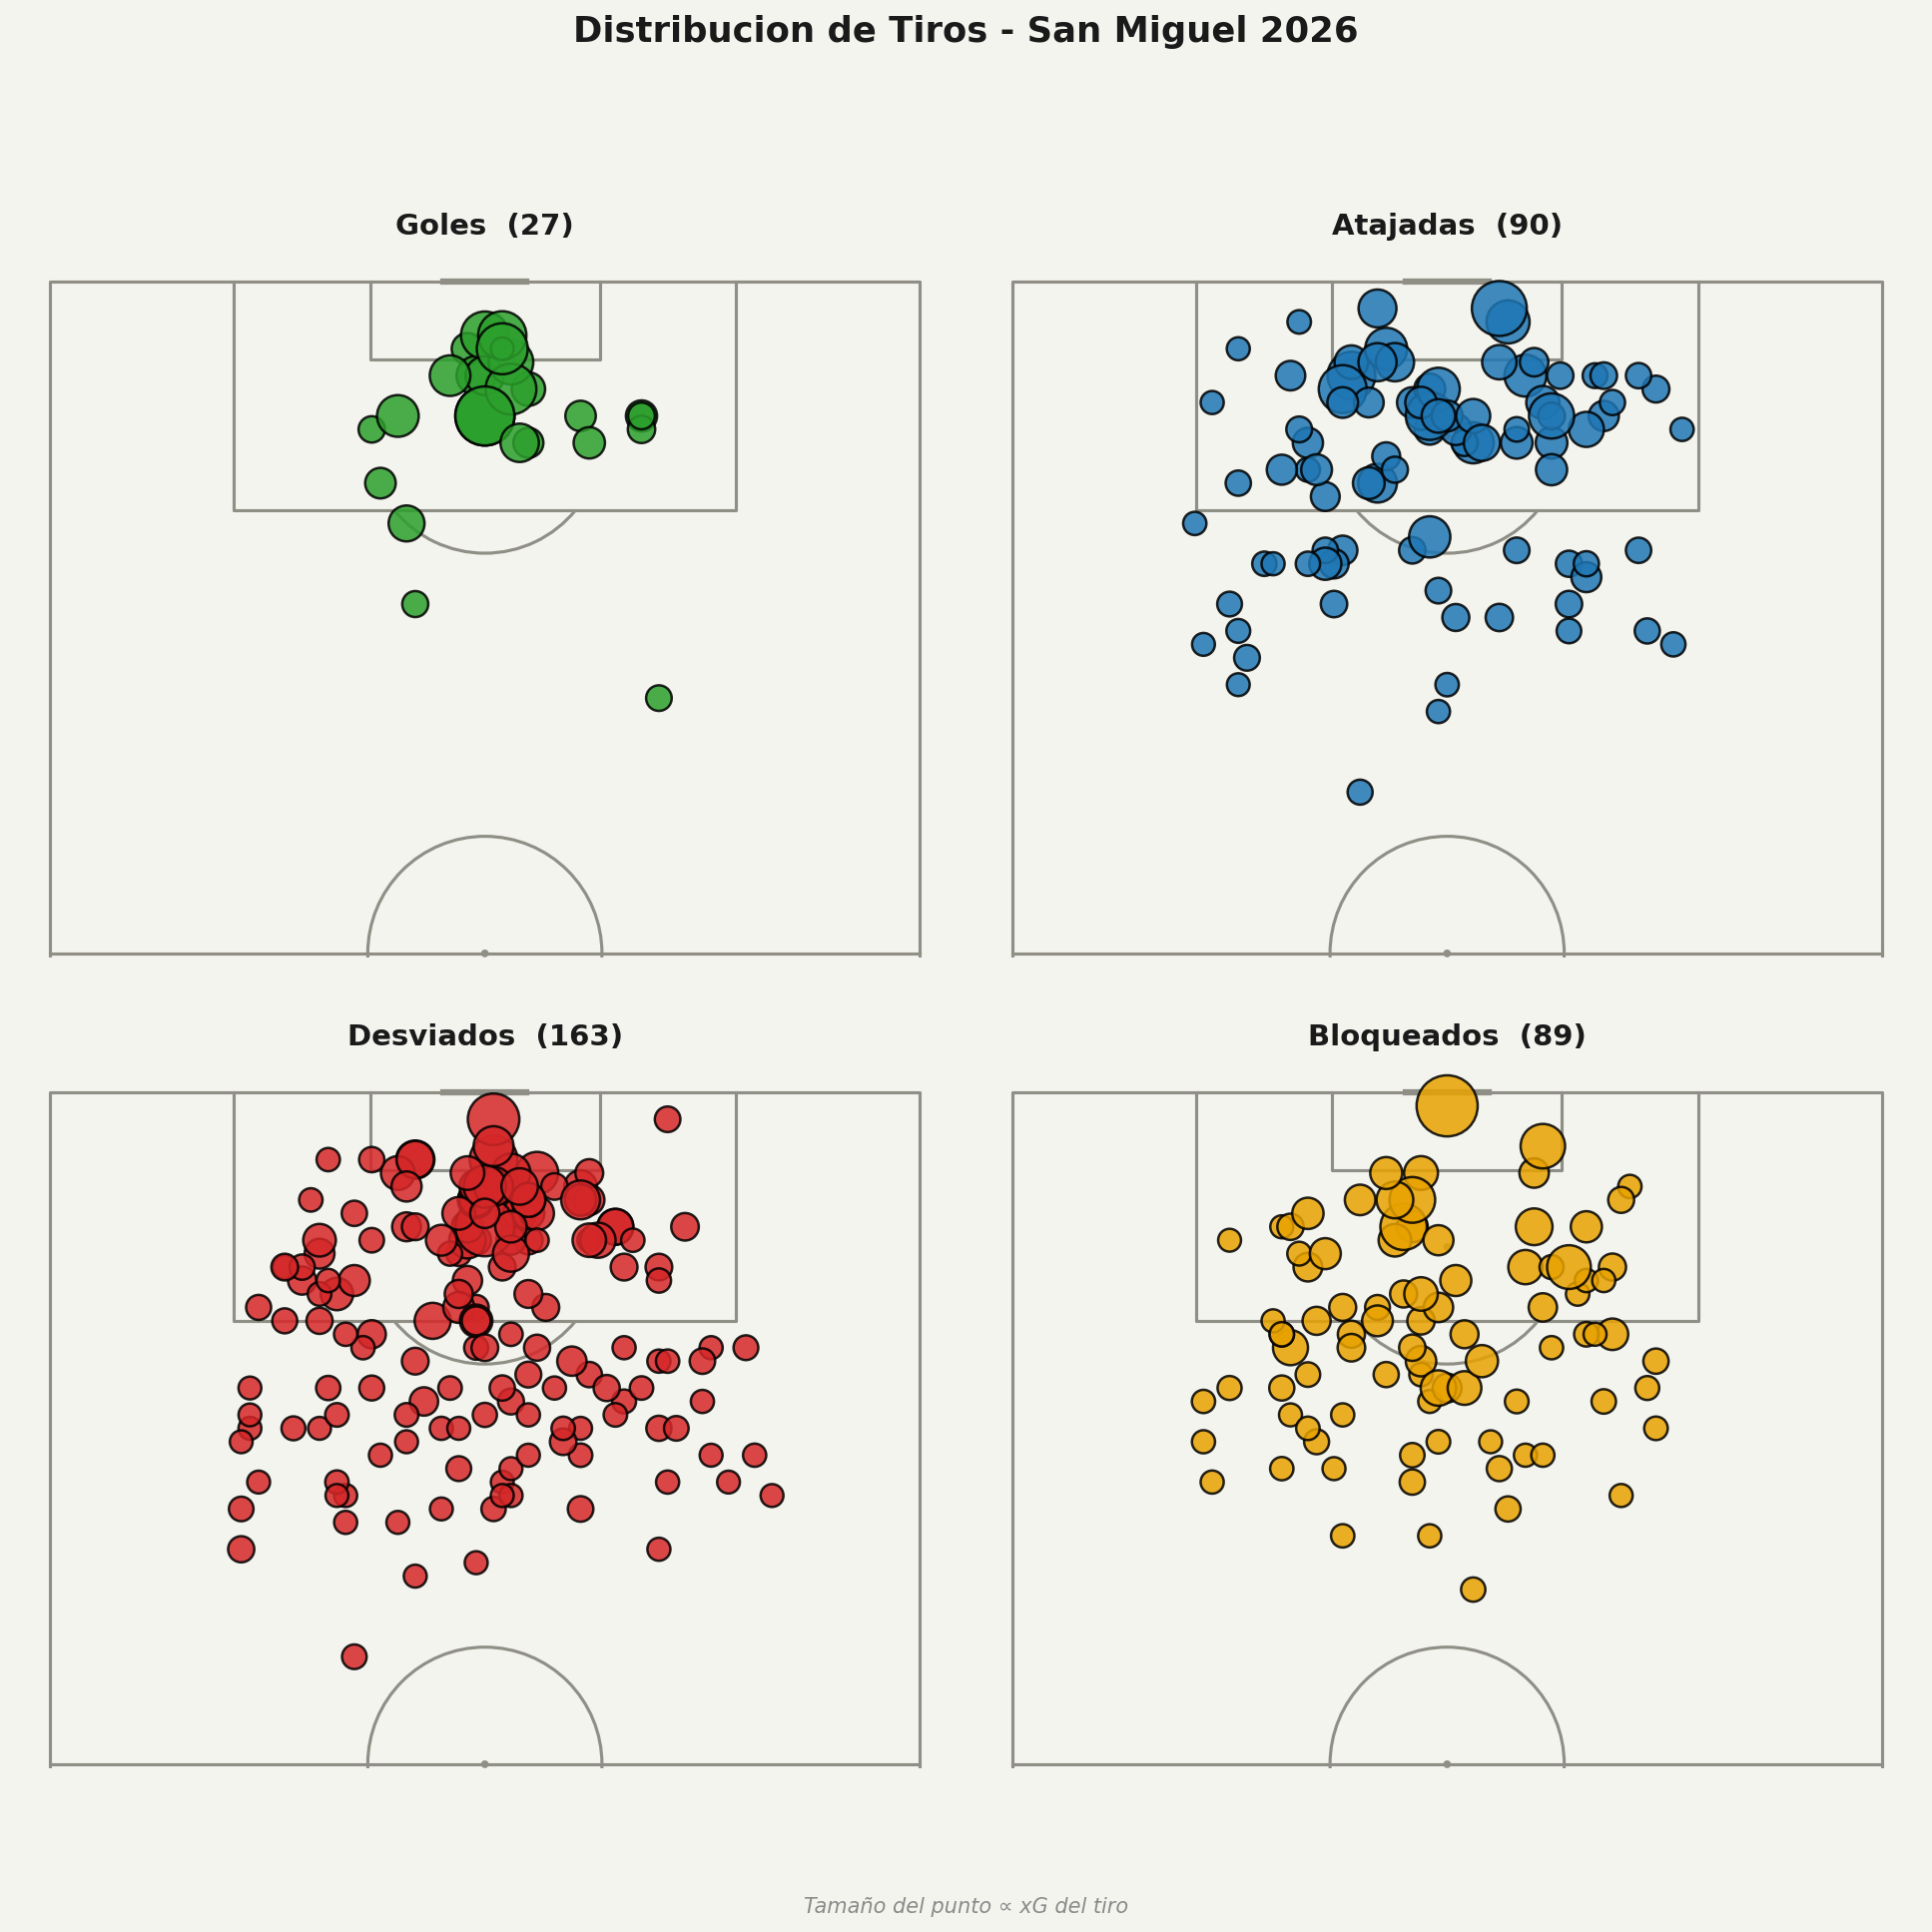

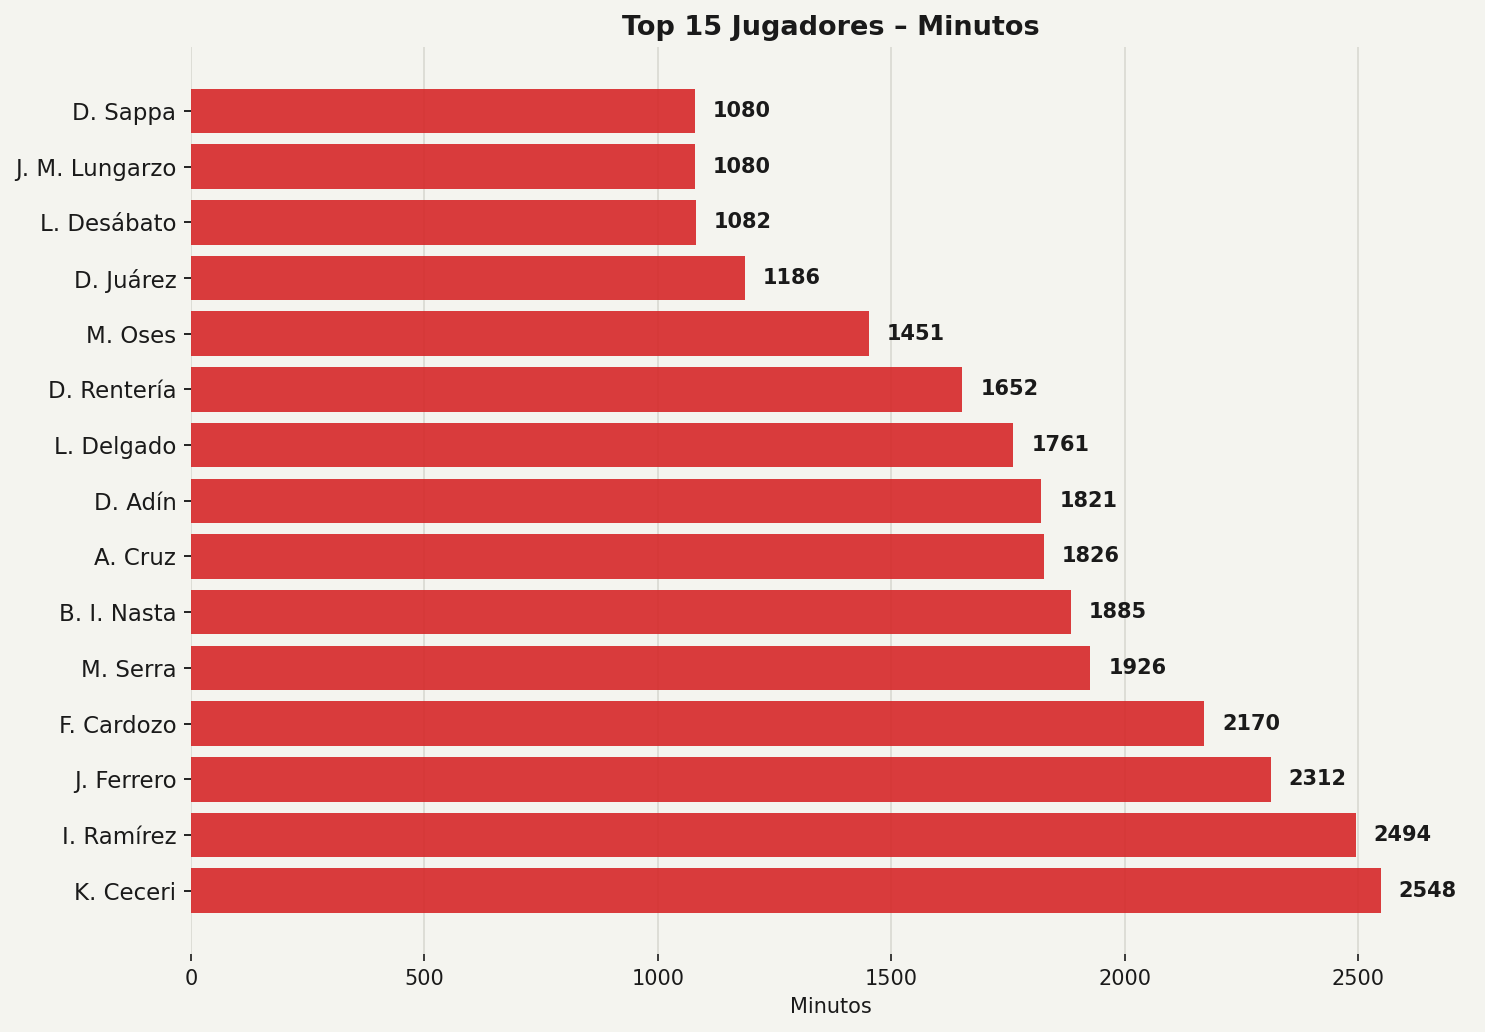

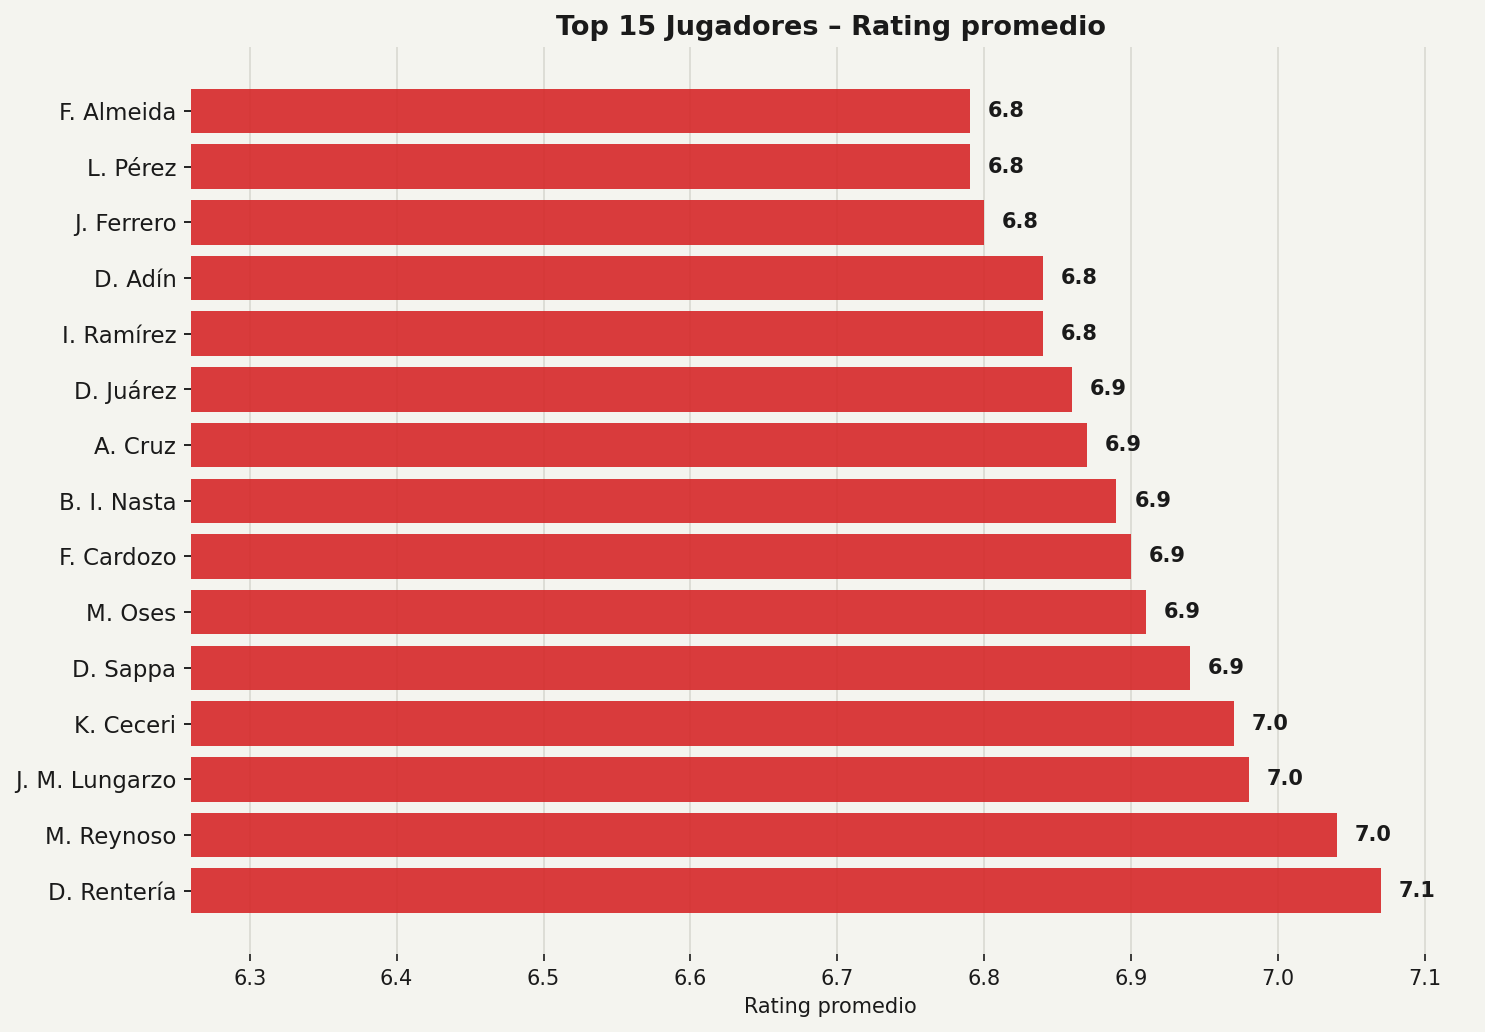

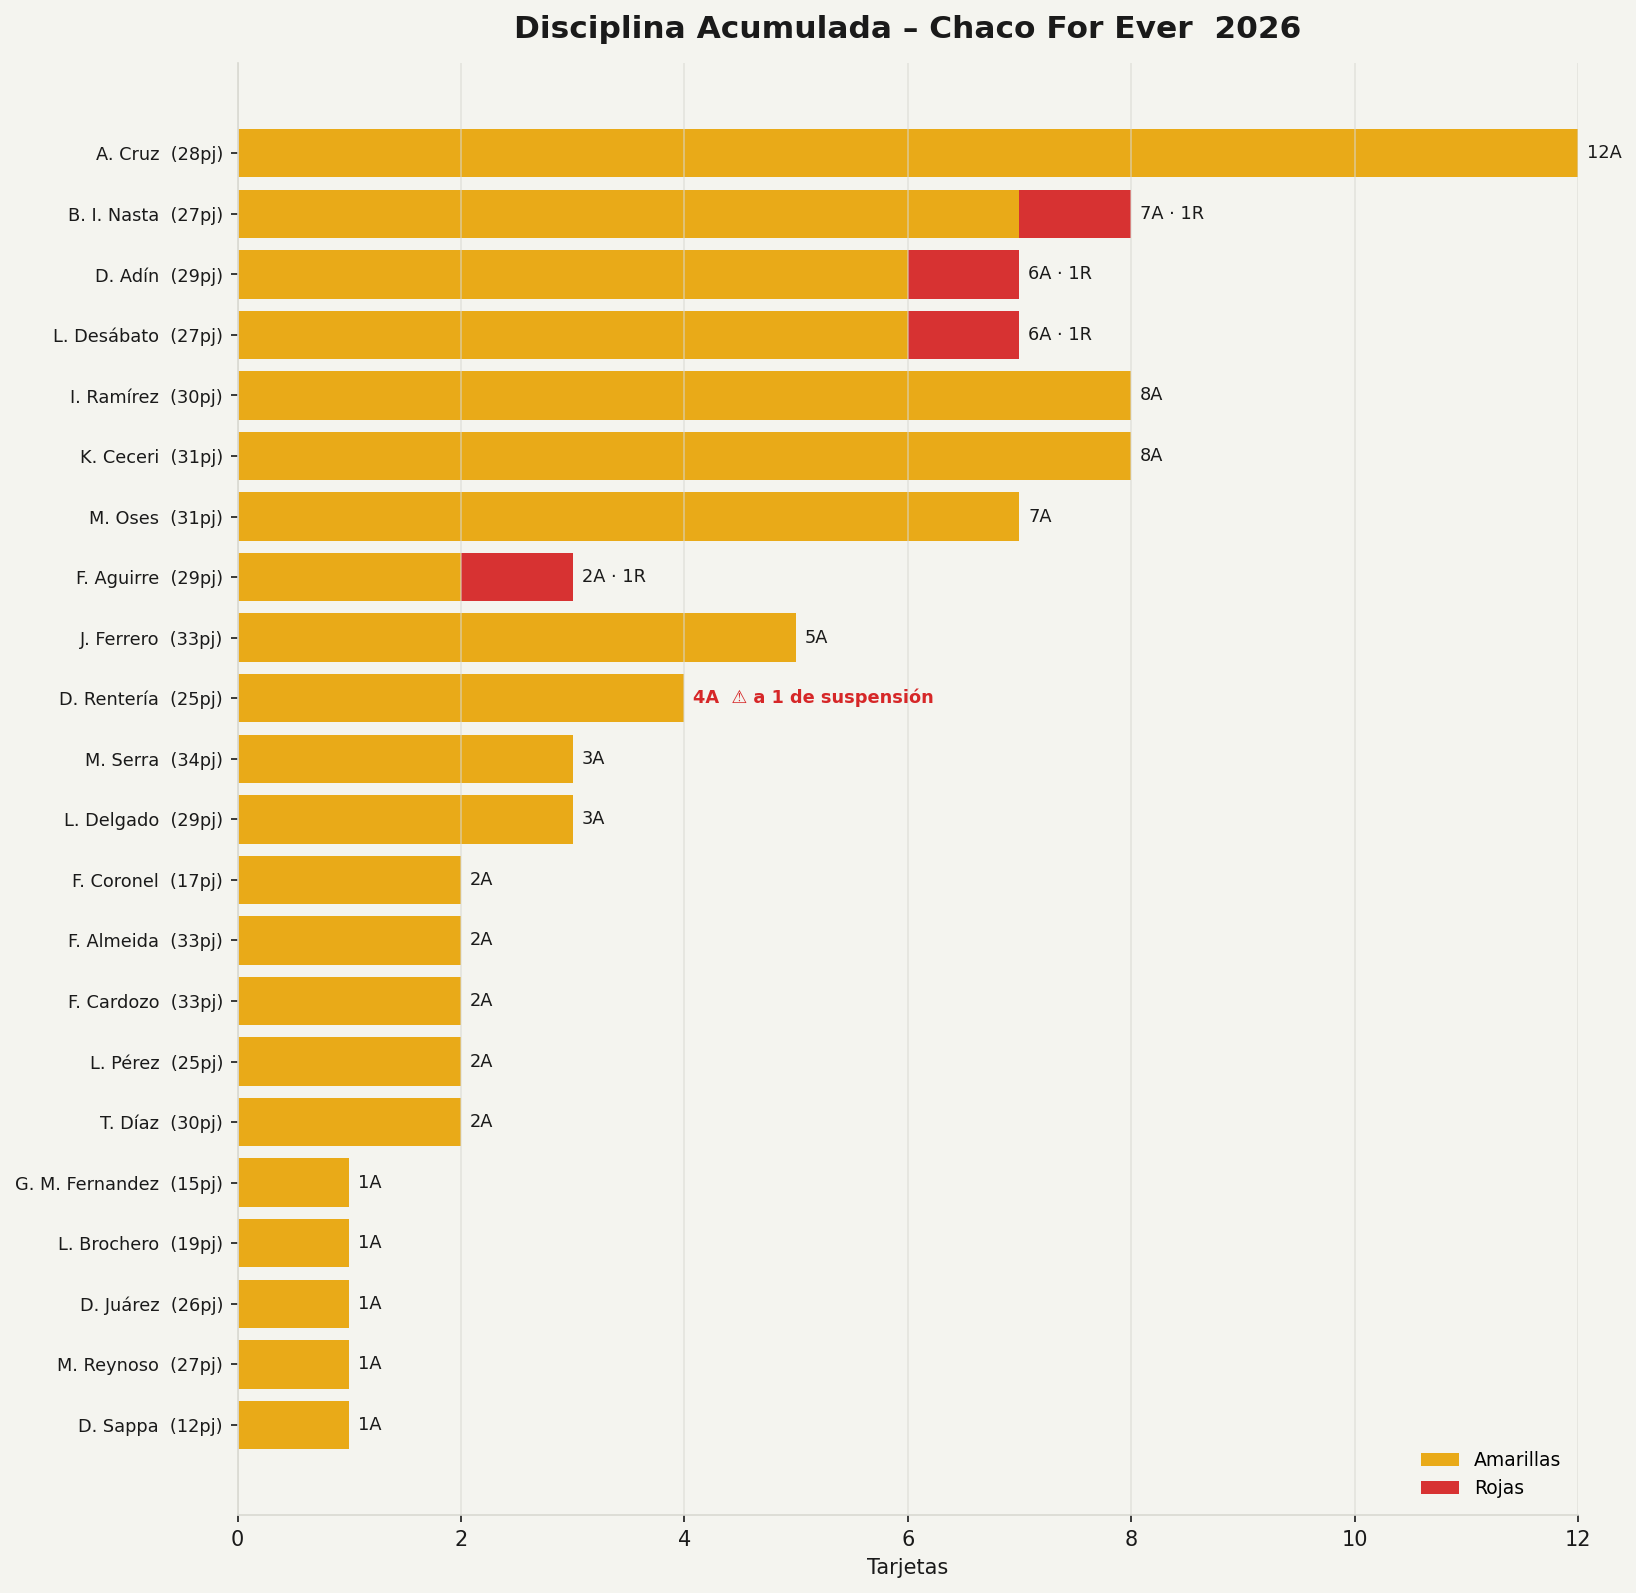

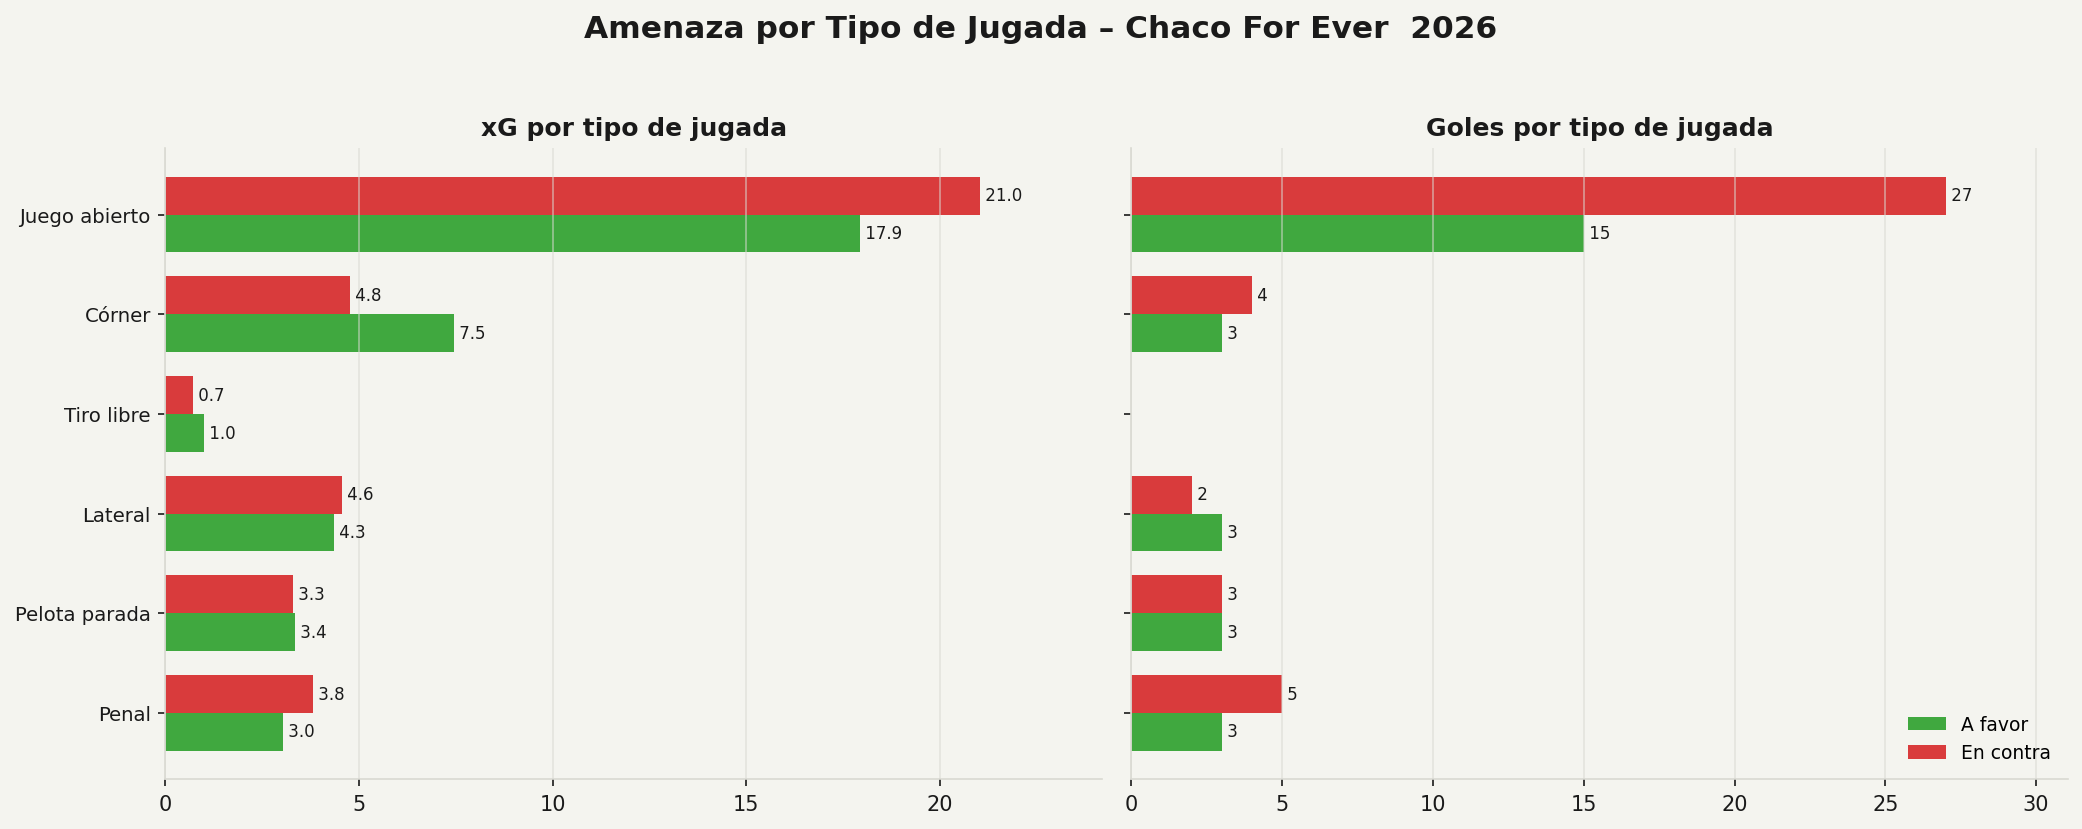

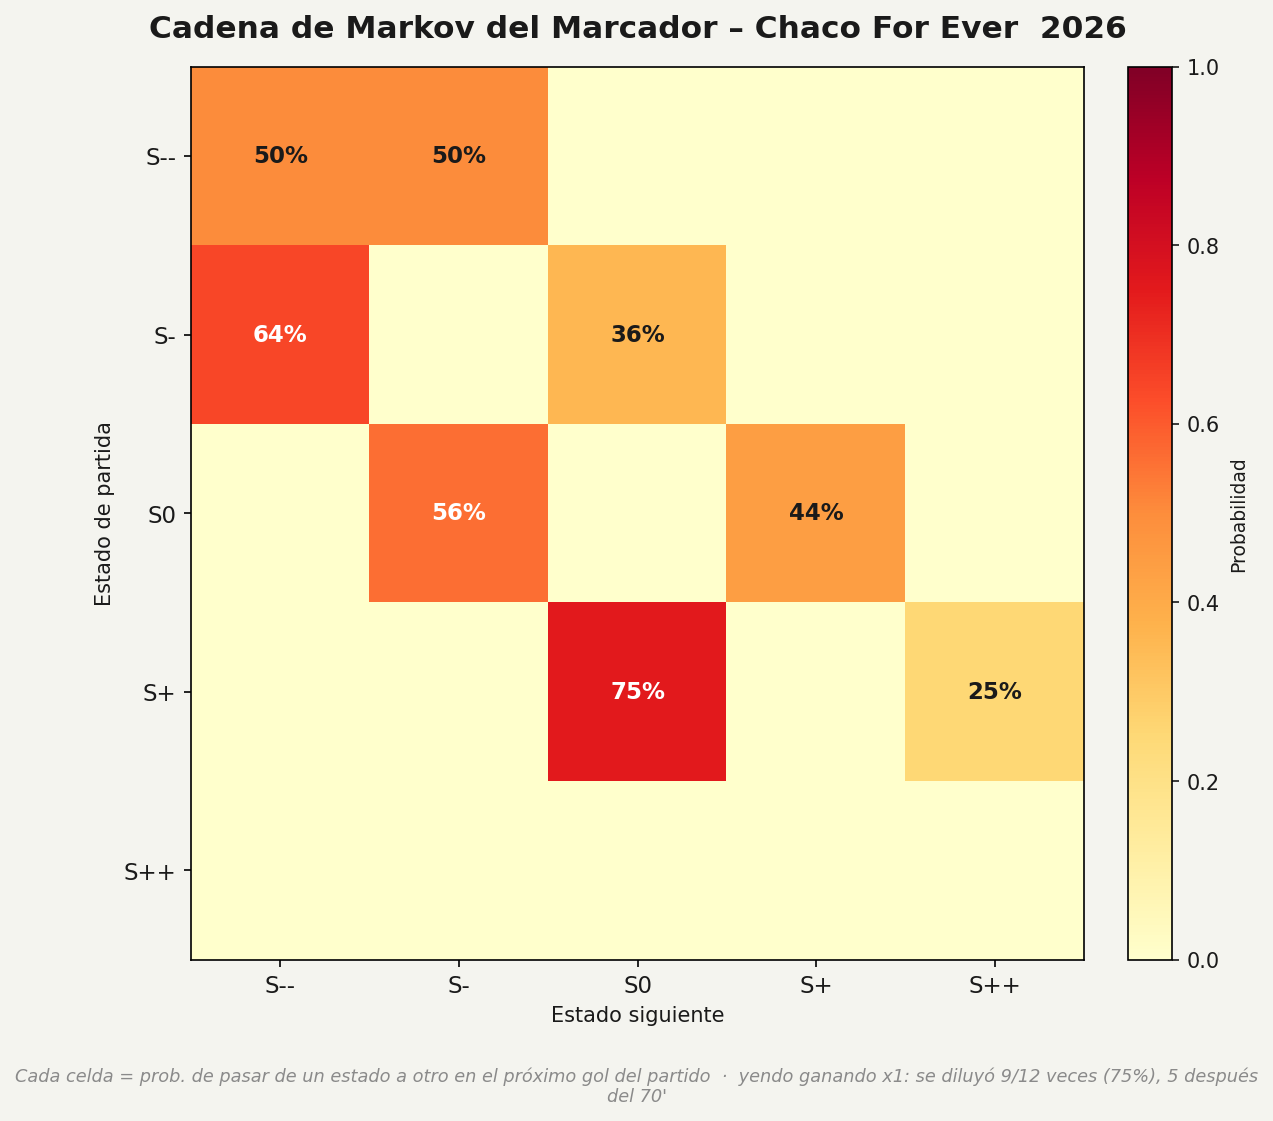

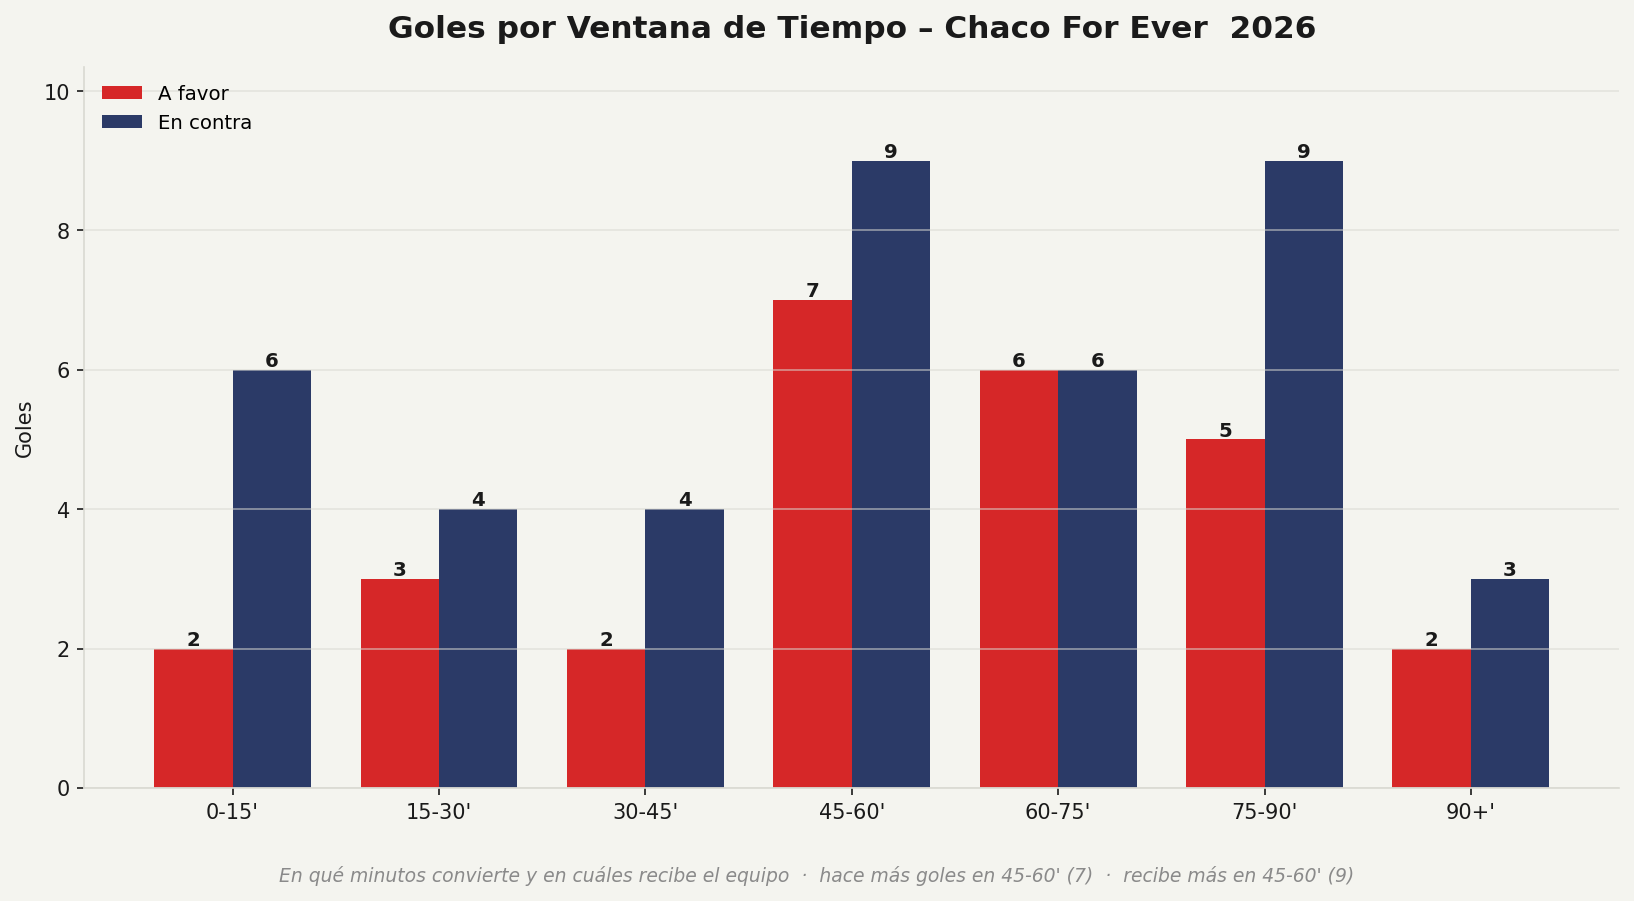

In [9]:
EQUIPO_DETALLE = 'san_miguel'    # slug del proximo rival

nombre = config.RIVALS[EQUIPO_DETALLE]['name']
d = temporadas.get(EQUIPO_DETALLE)
if not d:
    stats, season_df, player_df = analisis_temporada_equipo(EQUIPO_DETALLE, SEASON)
else:
    stats, season_df, player_df = d['stats'], d['season_df'], d['player_df']

if stats:
    print(f"=== {nombre} · Temporada {SEASON} ===")
    print(f"{stats['partidos']} PJ | {stats['victorias']}V-{stats['empates']}E-{stats['derrotas']}D "
          f"| {stats['puntos']} pts")
    print(f"Goles: {stats['goles_favor']} a favor / {stats['goles_contra']} en contra")
    print(f"xG: {stats['xg_favor']} favor / {stats['xg_contra']} contra")
    print(f"Local: {stats['rendimiento_local']}  |  Visitante: {stats['rendimiento_visitante']}\n")
    print(season_df[['date', 'opponent', 'venue', 'result', 'chaco_goals', 'rival_goals']]
          .rename(columns={'chaco_goals': 'goles', 'rival_goals': 'goles_rival'})
          .to_string(index=False))

    if not player_df.empty:
        print('\n=== Goleadores ===')
        print(top_scorers(player_df).to_string(index=False))
        print('\n=== Mas utilizados ===')
        print(most_used_players(player_df).to_string(index=False))

    plots_dir = config.rival_plots_dir(EQUIPO_DETALLE, SEASON)
    for f in ['puntos_acumulados.png', 'xg_temporada.png', 'forma_reciente.png',
              'local_visitante.png', 'shotmap_temporada.png', 'top_minutos.png',
              'top_rating.png', 'disciplina.png', 'amenaza_por_situacion.png',
              'markov_estado_marcador.png', 'goles_por_ventana.png']:
        show(os.path.join(plots_dir, f))
